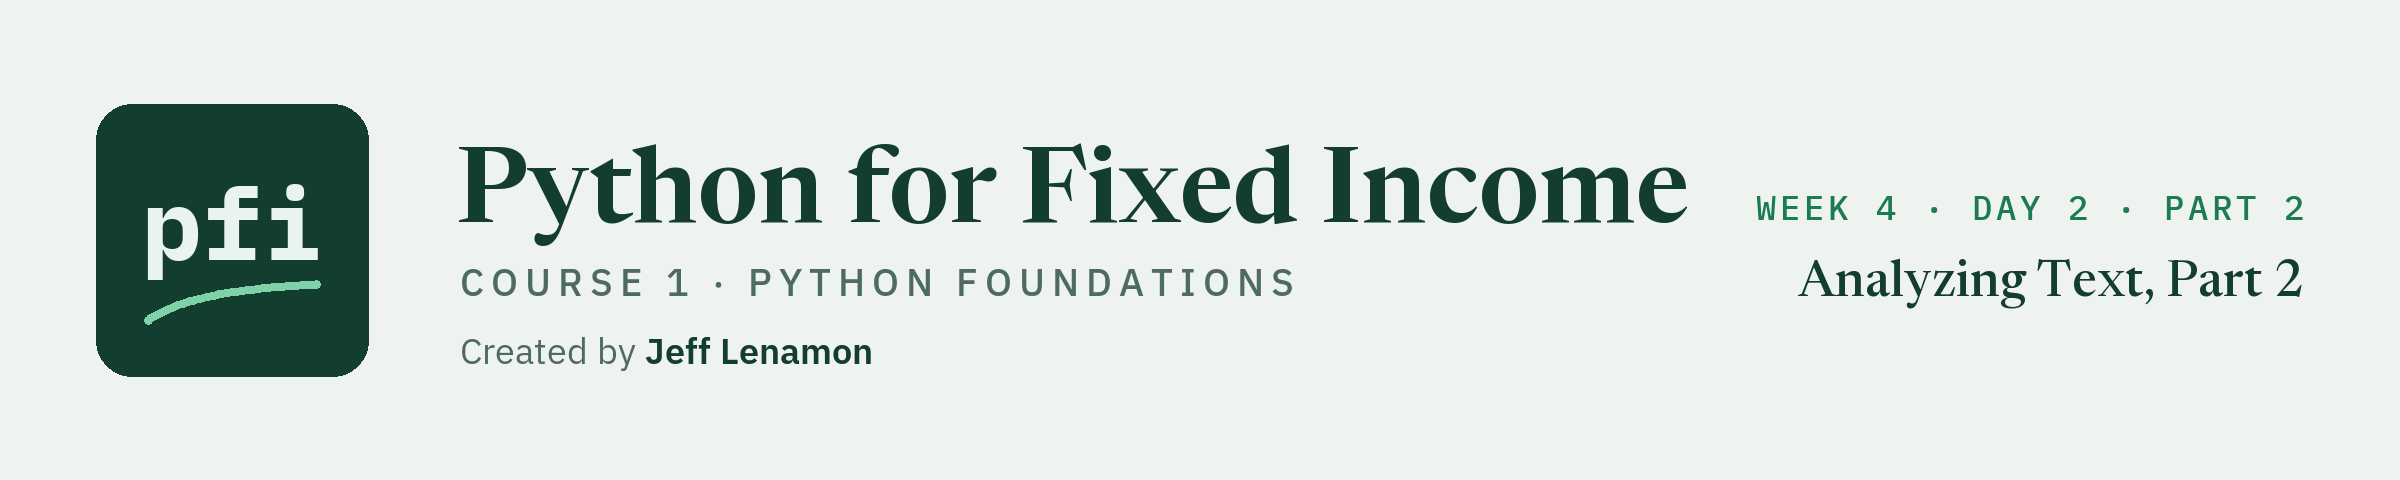

# Analyzing Text, Part 2

Week 4, Day 2, Part 2. Clean a statement in steps, count its words, and do the same to a table of 46 statements.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


In [2]:
# the libraries, as in Part 1 and the weeks before it
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# on your own machine the file is in the repo's data folder. In Colab it is read from GitHub.
if os.path.exists('../../../data/fomc_statements.csv'):
    data_file = '../../../data/fomc_statements.csv'
else:
    data_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/fomc_statements.csv'

statements = pd.read_csv(data_file)

# the statement dated 2023-11-01, as a plain Python string
statement = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]

# the second sentence of its third paragraph, with its full stop put back
sentence = statement.split('\n')[2].split('. ')[1] + '.'

# the pattern for a range: a figure, the word to, a figure, and percent
range_pattern = r'[\d/-]+ to [\d/-]+ percent'

print('Rows and columns:', statements.shape)
print('Characters in the statement dated 2023-11-01:', len(statement))
print('Statement dated 2023-11-01:', sentence)

Rows and columns: (46, 3)
Characters in the statement dated 2023-11-01: 2300
Statement dated 2023-11-01: In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.


Nothing here is new.

Part 1 built all of it, one step at a time.

In Part 1 the desk took one statement apart: its figures, its list of names, and the patterns that find them.

The portfolio manager's table is still empty.

The table needs, for each of the 46 statements, how long it is, which figures it contains, how often a short list of words appears, and how much of its wording is shared with the statement before it.

A count needs words, and a statement as published holds capitals, punctuation, and digits stuck to them.

So the text is cleaned first, one step at a time, on one sentence and then on one statement.

Then the same work goes to every row at once, and each result is a column of numbers.

**What this notebook does and does not do.** It counts.

It reports that a word appears a number of times in the statement of a given date, or that a word count went from one number to another.

It does not say what a statement means, what the Committee did or will do, or why any wording changed.

It scores no tone and makes no forecast.

Reading policy is a different job, and it is not taught here.

The order of work in this part:

1. **Cleaning.** Lower case, punctuation, white space, and splitting into words, one step at a time.
2. **Stopwords.** Removing the words that every English text is full of.
3. **Stemming.** Cutting words down to a common root.
4. **Text into numbers.** Counts for every statement, held in a table and drawn as charts.

**The data.** The text is real and public, and it is the only data in this notebook.

Source: Board of Governors of the Federal Reserve System, Federal Open Market Committee statements, federalreserve.gov.

Each statement was downloaded from its own press release page, which is linked from the calendar page https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm.

Retrieved on 2026-10-03.

Span: the 46 statements from 2021-01-27 to 2026-09-16, which is every scheduled meeting of 2021 to 2025 and of 2026 up to the retrieval date.

Reuse: the Board's website says, at https://www.federalreserve.gov/disclaimer.htm, "Unless otherwise indicated, information on Board's website is in the public domain and may be copied and distributed without permission. Please cite to the Board as the source of the information."

The text in the file is exactly as published.

The only change made when the file was built was to white space: one space between words, and one line break between paragraphs.

When this notebook quotes a statement, it prints the words from the file and gives the statement's date.

## 17.4 Cleaning Text in Steps

To count words, the text has to be cut into words, and two spellings of one word have to become one.

`Inflation` and `inflation` are the same word to a reader and two different strings to Python.

`percent.` with a full stop and `percent` are the same word too.

Cleaning is done in small steps, each one printed, on one sentence: the sentence stored as `sentence` in the first code cell of this notebook.

Q. Step 0. Show the sentence as it is, and split it with no cleaning.

In [3]:
print('Statement dated 2023-11-01:')
print(sentence)

raw_words = sentence.split()
print(raw_words)
print('Pieces:', len(raw_words))

Statement dated 2023-11-01:
In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.
['In', 'support', 'of', 'these', 'goals,', 'the', 'Committee', 'decided', 'to', 'maintain', 'the', 'target', 'range', 'for', 'the', 'federal', 'funds', 'rate', 'at', '5-1/4', 'to', '5-1/2', 'percent.']
Pieces: 23


23 pieces.

Among them are `'In'` with a capital, `'goals,'` with a comma, `'percent.'` with a full stop, and the figures `'5-1/4'` and `'5-1/2'`.

Q. Step 1. Lower case.

In [4]:
step1 = sentence.lower()
print(step1)

in support of these goals, the committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.


`In` became `in` and `Committee` became `committee`.

Nothing else changed.

Q. Step 2. Replace every character that is not a letter or white space with a space.

In [5]:
# [^a-z\s] is one character that is not a lower-case letter and not white space
step2 = re.sub(r'[^a-z\s]', ' ', step1)
print(step2)

in support of these goals  the committee decided to maintain the target range for the federal funds rate at       to       percent 


The comma, the full stop, the hyphens, the slashes, and the digits are gone, each replaced by a space.

**Dropping the digits is a decision.** This notebook cleans text in order to count words, and `5`, `1`, and `4` are not words.

The figures are not lost: section 17.3 took them from the text as published, before any cleaning.

Had the job been to count figures, the digits would stay.

The replacement is a space and not an empty string.

With an empty string, `5-1/4` would close up, and so would a word like `longer-run`, which would become `longerrun`.

The order matters.

Lower case came first, so the class `[a-z]` covers every letter.

Q. Step 3. Reduce every run of white space to one space.

In [6]:
# \s+ is one or more white space characters. strip() removes the space left at the end.
step3 = re.sub(r'\s+', ' ', step2).strip()
print(step3)

in support of these goals the committee decided to maintain the target range for the federal funds rate at to percent


Where the figures were there is now one space, not a gap.

`\s` also matches a line break, so on a whole statement this step joins the paragraphs into one line.

Q. Step 4. Split into words.

In [7]:
tokens = step3.split(' ')
print(tokens)
print('Tokens:', len(tokens), ' pieces before cleaning:', len(raw_words))

['in', 'support', 'of', 'these', 'goals', 'the', 'committee', 'decided', 'to', 'maintain', 'the', 'target', 'range', 'for', 'the', 'federal', 'funds', 'rate', 'at', 'to', 'percent']
Tokens: 21  pieces before cleaning: 23


21 tokens, from 23 pieces.

The two figures are gone, and every token is a lower-case word with nothing attached.

A **token** is one unit of text after cleaning.

Here a token is a word.

Cutting text into tokens is called tokenizing.

Q. Put the four steps into one function.

In [8]:
def clean(text):
    # step 1: lower case
    text = text.lower()
    # step 2: every character that is not a letter or white space becomes a space
    text = re.sub(r'[^a-z\s]', ' ', text)
    # step 3: one space between words, none at the ends
    text = re.sub(r'\s+', ' ', text).strip()
    # step 4: a list of tokens
    return text.split(' ')


print(clean(sentence) == tokens)

True


`True`: the function gives the same 21 tokens as the four steps did.

**Predict 1**

The statement holds a short phrase with an apostrophe in it.

The next cell finds it with a pattern and cleans it.

How many tokens does `clean()` return for `the Committee's goals.`?

> A) 3: `the`, `committees`, `goals`.
>
> B) 3: `the`, `committee`, `goals`.
>
> C) 4.

Decide, then run the cell.

In [9]:
# the, a word, an apostrophe and an s, a word, and a full stop
phrase = re.search(r"the \w+'s \w+\.", statement).group(0)
print(phrase)

print(clean(phrase))
print('Tokens:', len(clean(phrase)))

the Committee's goals.
['the', 'committee', 's', 'goals']
Tokens: 4


The answer is C. The apostrophe became a space, which left the `s` standing as a token of its own: `the`, `committee`, `s`, `goals`.

That is a limit of this simple cleaning, and it is better to know it than to be surprised by an `s` in a list of common words.

Q. Clean the whole statement. How many tokens?

In [10]:
statement_tokens = clean(statement)

print('Words by split():', len(statement.split()))
print('Tokens after cleaning:', len(statement_tokens))
print('First ten:', statement_tokens[:10])

Words by split(): 344
Tokens after cleaning: 343
First ten: ['recent', 'indicators', 'suggest', 'that', 'economic', 'activity', 'expanded', 'at', 'a', 'strong']


344 pieces by a plain `split()` and 343 tokens after cleaning.

The totals are close, and the lists are not the same: cleaning removed the figures and split some pieces in two.

**Excel side by side.** With a sentence in A2, the same steps as formulas:

<table align="left">
<tr><th align="left">Step</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Lower case</td><td align="left"><code>text.lower()</code></td><td align="left"><code>=LOWER(A2)</code></td></tr>
<tr><td align="left">Remove one kind of character</td><td align="left"><code>text.replace(',', ' ')</code></td><td align="left"><code>=SUBSTITUTE(A2, ",", " ")</code></td></tr>
<tr><td align="left">Remove everything but letters and spaces</td><td align="left"><code>re.sub(r'[^a-z\s]', ' ', text)</code></td><td align="left"><code>=REGEXREPLACE(LOWER(A2), "[^a-z\s]", " ")</code></td></tr>
<tr><td align="left">One space between words</td><td align="left"><code>re.sub(r'\s+', ' ', text).strip()</code></td><td align="left"><code>=TRIM(B2)</code></td></tr>
<tr><td align="left">Split into words</td><td align="left"><code>text.split(' ')</code></td><td align="left"><code>=TEXTSPLIT(C2, " ")</code></td></tr>
</table>
<br clear="left">

`TRIM` works on ordinary spaces only, and `\s` also covers tabs, line breaks, and non-breaking spaces.

A cell that holds a line break or a non-breaking space needs `=SUBSTITUTE(B2, CHAR(10), " ")` or `=SUBSTITUTE(B2, CHAR(160), " ")` before `TRIM`.

Without `REGEXREPLACE`, the second step is one `SUBSTITUTE` for each character to remove, nested inside each other: `=SUBSTITUTE(SUBSTITUTE(LOWER(A2), ",", " "), ".", " ")` and so on for the hyphen, the slash, and each digit.

It works, and the formula grows with every character.

## 17.5 Stopwords

Q. Which tokens are the most common in the statement?

In [11]:
# collections comes with Python, so there is nothing to install
from collections import Counter

# Counter takes a list and counts how many times each value appears
counts = Counter(statement_tokens)

print('Different tokens:', len(counts))

# most_common(10) returns the 10 highest counts as (token, count) pairs
print(counts.most_common(10))

Different tokens: 180
[('the', 29), ('and', 16), ('to', 12), ('of', 11), ('committee', 11), ('inflation', 9), ('in', 7), ('policy', 7), ('monetary', 6), ('economic', 5)]


180 different tokens among the 343.

The most common is `the`, 29 times, then `and` 16, `to` 12, and `of` 11.

`committee` appears 11 times and `inflation` 9.

`Counter` is a dictionary with counting built in.

`counts['inflation']` returns 9, and a token that is not there returns 0.

The top of the list would look much the same for any English text.

Words like `the`, `and`, and `of` hold a sentence together and say nothing about what it is about.

They are called **stopwords**, and for counting they are usually removed.

**Excel side by side.** With the 343 tokens in B2:B344, `=COUNTIF(B2:B344, "the")` returns 29.

A pivot table with the token in Rows and Count of the token in Values, sorted largest first, gives the whole list.

Q. Remove a short list of stopwords, typed by hand.

In [12]:
# ten common English words
short_list = ['the', 'of', 'to', 'and', 'a', 'in', 'is', 'that', 'for', 'its']

# keep a token only if it is not on the list
short_kept = [token for token in statement_tokens if token not in short_list]

print('Tokens before:', len(statement_tokens))
print('Tokens after:', len(short_kept))
print('Removed:', len(statement_tokens) - len(short_kept))
print(Counter(short_kept).most_common(10))

Tokens before: 343
Tokens after: 252
Removed: 91
[('committee', 11), ('inflation', 9), ('policy', 7), ('monetary', 6), ('economic', 5), ('will', 5), ('s', 4), ('percent', 4), ('activity', 3), ('at', 3)]


Ten words on the list removed 91 of the 343 tokens, more than a quarter, and left 252.

The list is a choice, and a short one misses things: `will`, `at`, and the stray `s` are still near the top.

`nltk`, the Natural Language Toolkit, is a library for working with text, and it is in the course's `requirements.txt`.

It ships a longer list.

Q. Load nltk's English stopword list.

In [13]:
import nltk

# the word list is a small file that nltk downloads once and keeps on this machine
# quiet=True stops the download from printing its progress
ready = nltk.download('stopwords', quiet=True)
print('Stopword list ready:', ready)

from nltk.corpus import stopwords

stop_words = stopwords.words('english')

print('Words on the list:', len(stop_words))
print('First ten:', stop_words[:10])
print("Is 's' on the list?", 's' in stop_words)

Stopword list ready: True
Words on the list: 198
First ten: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']
Is 's' on the list? True


198 words.

The first time this cell runs it needs an internet connection for the download.

After that the list is read from the machine. nltk revises the list from time to time.

If your count is not 198, the counts later in this notebook will differ a little from the ones printed here.

The list is in lower case, which is one more reason the text was put in lower case first.

The single letter `s` is on it, so the stray `s` from `Committee's` goes too.

Q. Remove nltk's stopwords from the statement.

In [14]:
kept = [token for token in statement_tokens if token not in stop_words]

print('Tokens before:', len(statement_tokens))
print('After the short list:', len(short_kept))
print('After the nltk list:', len(kept))
print('Different tokens before:', len(set(statement_tokens)), ' after:', len(set(kept)))
print(Counter(kept).most_common(10))

Tokens before: 343
After the short list: 252
After the nltk list: 217
Different tokens before: 180  after: 152
[('committee', 11), ('inflation', 9), ('policy', 7), ('monetary', 6), ('economic', 5), ('percent', 4), ('activity', 3), ('rate', 3), ('remains', 3), ('financial', 3)]


217 tokens are left of the 343: the list removed 126.

The number of different tokens went from 180 to 152.

In the statement dated 2023-11-01, after cleaning and stopword removal, the most common tokens are `committee` 11 times, `inflation` 9, `policy` 7, `monetary` 6, and `economic` 5.

A set holds each different value once, as in notebook 08, so `len(set(tokens))` is the number of different tokens.

That list is a count and nothing more.

It says which words appear most often in one document.

It does not say what the document concludes.

**Excel side by side.** With the 343 tokens in B2:B344 and the stopword list in column A of a sheet named `stop`:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Is this token a stopword?</td><td align="left"><code>token in stop_words</code></td><td align="left"><code>=COUNTIF(stop!A:A, B2) &gt; 0</code>, filled down</td><td align="left">TRUE or FALSE</td></tr>
<tr><td align="left">Tokens that are not stopwords</td><td align="left">the list comprehension</td><td align="left"><code>=FILTER(B2:B344, COUNTIF(stop!A:A, B2:B344) = 0)</code></td><td align="left">217 tokens</td></tr>
<tr><td align="left">How many are left</td><td align="left"><code>len(kept)</code></td><td align="left"><code>=SUMPRODUCT(--(COUNTIF(stop!A:A, B2:B344) = 0))</code></td><td align="left">217</td></tr>
</table>
<br clear="left">

`FILTER` is in Excel 2021 and Microsoft 365.

The `SUMPRODUCT` count works in every version.

## 17.6 Stemming

The statement of 2023-11-01 has `remain`, `remained`, and `remains`.

To a count they are three different tokens.

**Stemming** cuts the ending off a word, so that forms of one word are counted together.

What is left is called the **stem**.

`nltk` has several stemmers.

The Porter stemmer is the classic one: a fixed list of rules about English endings.

It needs no download.

Q. Stem a few tokens from the statement.

In [15]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# stem() takes one word and returns its stem
for word in ['remain', 'remained', 'remains', 'assess', 'assessing', 'assessments']:
    print(word, '->', stemmer.stem(word))

remain -> remain
remained -> remain
remains -> remain
assess -> assess
assessing -> assess
assessments -> assess


`remain`, `remained`, and `remains` all become `remain`.

`assess`, `assessing`, and `assessments` all become `assess`.

Q. Stem some more.

In [16]:
for word in ['inflation', 'policy', 'committee', 'monetary', 'securities']:
    print(word, '->', stemmer.stem(word))

inflation -> inflat
policy -> polici
committee -> committe
monetary -> monetari
securities -> secur


`inflat`, `polici`, `committe`, `monetari`, `secur`.

**A stem is not a word.** The stemmer does not look anything up in a dictionary.

It applies rules to the letters: drop `ion`, turn a final `y` into `i`, and so on.

The result is a label for a family of words, and it is not meant to be read.

**Predict 2**

`economic` and `economy` are both in the statements.

Does the Porter stemmer give them the same stem?

> A) Yes, both become `econom`.
>
> B) No.

Decide, then run the cell.

In [17]:
for word in ['economic', 'economy']:
    print(word, '->', stemmer.stem(word))

for word in ['production', 'productivity', 'reserve', 'reserves', 'time', 'timing']:
    print(word, '->', stemmer.stem(word))

economic -> econom
economy -> economi
production -> product
productivity -> product
reserve -> reserv
reserves -> reserv
time -> time
timing -> time


The answer is B. `economic` becomes `econom` and `economy` becomes `economi`.

Two forms a reader would put together stay apart.

The second group shows the opposite.

`production` and `productivity` are different words and share the stem `product`.

So do `time` and `timing`, with the stem `time`.

These are the two limits of stemming: it can keep related words apart, and it can merge words that are not the same.

All eight words are in the statements.

A stem count is a rougher count than a word count, and it should be labelled as a stem count.

Q. What does stemming do to the counts for the statement?

In [18]:
# stem every token that was kept after stopword removal
stems = [stemmer.stem(token) for token in kept]

print('Tokens:', len(kept), ' stems:', len(stems))
print('Different tokens:', len(set(kept)))
print('Different stems:', len(set(stems)))
print(Counter(stems).most_common(6))

Tokens: 217  stems: 217
Different tokens: 152
Different stems: 146
[('committe', 11), ('inflat', 9), ('polici', 7), ('monetari', 6), ('econom', 5), ('remain', 5)]


Still 217 items, because stemming changes each token and removes none.

The number of different items falls from 152 to 146.

The count for `remain` is now 5, where the word `remains` had 3: the stem gathers `remain`, `remained`, and `remains`.

The rest of this notebook counts tokens, not stems, so that every number can be checked against the text by eye.

Stemming is a tool to reach for when the forms of a word need to be counted as one.

**Excel side by side.** Excel has no function for stemming.

The nearest hand tool is a wildcard: `=COUNTIF(B2:B344, "remain*")` counts every token that starts with `remain`, and returns 5.

## 17.7 Text Into Numbers

Everything so far was done to one statement.

The table has 46.

This section does the same work to every row at once, and each result is a column of numbers.

### String Methods on a Column

Q. Put the text of every statement in lower case.

In [19]:
# the string method, called on the column
statements['text'].lower()

AttributeError: 'Series' object has no attribute 'lower'

An `AttributeError`, and the last line reads `'Series' object has no attribute 'lower'`.

`lower()` belongs to a string.

`statements['text']` is not a string.

It is a Series that holds 46 strings, and a Series has no `lower()` of its own.

pandas keeps the string methods of a column behind `.str`, as notebook 13 used for `.str.strip()` and `.str.upper()`.

Q. Do it with `.str`.

In [20]:
# .str applies the string method to every value in the column
lower_text = statements['text'].str.lower()

# the first 60 characters of the first statement, before and after
print('Statement dated', statements['date'].iloc[0])
print(statements['text'].iloc[0][:60])
print(lower_text.iloc[0][:60])

Statement dated 2021-01-27
The Federal Reserve is committed to using its full range of 
the federal reserve is committed to using its full range of 


All 46 texts in lower case, in one line.

In Excel this is `=LOWER(C2)` filled down 46 rows, with the text in column C.

Q. How long is each statement, in characters and in words?

In [21]:
# .str.len() gives the number of characters in each text
statements['characters'] = statements['text'].str.len()

# .str.split() gives a list of words for each text, and .str.len() gives the length of each list
statements['words'] = statements['text'].str.split().str.len()

# the first five rows, with a title and no row numbers
display(statements[['date', 'characters', 'words']].head().style.format({'characters': '{:,.0f}'}).hide(axis='index')
        .set_caption('Length of the first five statements'))
print('Mean words:', round(statements['words'].mean(), 1), ' median:', statements['words'].median())

# the longest and the shortest statement
longest = statements.loc[statements['words'].idxmax()]
shortest = statements.loc[statements['words'].idxmin()]
print('Longest:', longest['date'], longest['words'], 'words')
print('Shortest:', shortest['date'], shortest['words'], 'words')

date,characters,words
2021-01-27,"3,200",485
2021-03-17,"3,168",480
2021-04-28,"3,156",476
2021-06-16,"3,119",474
2021-07-28,"3,202",488


Mean words: 359.3  median: 344.5
Longest: 2021-11-03 614 words
Shortest: 2026-06-17 131 words


The statements average 359.3 words, with a median of 344.5.

The longest is the statement dated 2021-11-03, with 614 words.

The shortest is dated 2026-06-17, with 131 words.

`.str.len()` does two jobs here.

On a column of strings it counts characters.

On a column of lists it counts the items in each list.

Q. Draw the word count of each statement over time.

,count,mean,min,max
year,,,,
2021,8,505.5,474,614
2022,8,361.1,313,430
2023,8,342.5,331,365
2024,8,348.5,318,406
2025,8,337.5,295,386
2026,6,228.0,131,341


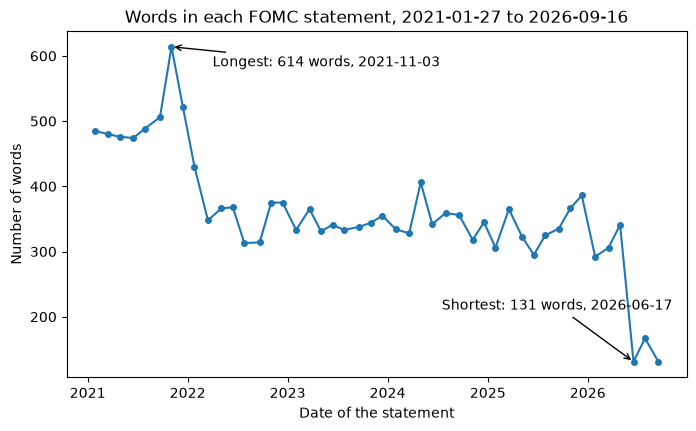

In [22]:
# real dates for the x axis, and the year of each statement for grouping later
statements['meeting'] = pd.to_datetime(statements['date'], format='%Y-%m-%d')
statements['year'] = statements['meeting'].dt.year

# the same two rows again, now that they hold the real dates
longest = statements.loc[statements['words'].idxmax()]
shortest = statements.loc[statements['words'].idxmin()]

by_year_words = statements.groupby('year')['words'].agg(['count', 'mean', 'min', 'max'])
display(by_year_words.style.format({'count': '{:.0f}', 'mean': '{:.1f}', 'min': '{:.0f}', 'max': '{:.0f}'})
        .bar(subset=['mean'], color='#8fc9ae').set_caption('Words in a statement, by year'))

fig, ax = plt.subplots(figsize=(8, 4.5))

# one point for each statement, joined by a line
ax.plot(statements['meeting'], statements['words'], marker='o', markersize=4)

# pd.Timedelta(days=150) is a length of time: added to a date, it moves the note 150 days to the right
ax.annotate(f"Longest: {longest['words']} words, {longest['date']}", xy=(longest['meeting'], longest['words']),
            xytext=(longest['meeting'] + pd.Timedelta(days=150), longest['words'] - 30), arrowprops={'arrowstyle': '->'})

# subtracted from a date, it moves the note 700 days to the left
ax.annotate(f"Shortest: {shortest['words']} words, {shortest['date']}", xy=(shortest['meeting'], shortest['words']),
            xytext=(shortest['meeting'] - pd.Timedelta(days=700), shortest['words'] + 80), arrowprops={'arrowstyle': '->'})

ax.set_title('Words in each FOMC statement, 2021-01-27 to 2026-09-16')
ax.set_xlabel('Date of the statement')
ax.set_ylabel('Number of words')

plt.show()

By year, the mean word count is 505.5 in 2021, 361.1 in 2022, 342.5 in 2023, 348.5 in 2024, 337.5 in 2025, and 228.0 in the six statements of 2026.

On the chart the count is between 474 and 614 in 2021, between 295 and 430 from 2022 to 2025, and falls from 341 on 2026-04-29 to 131 on 2026-06-17.

The chart shows how long each statement is.

It does not show why, and a word count cannot.

Q. How many statements contain the word `balance`, and how many times does `inflation` appear in each?

In [23]:
# .str.contains() is True for each text where the pattern is found
has_balance = lower_text.str.contains(r'\bbalance\b')
print('Statements that contain the word balance:', has_balance.sum(), 'of', len(statements))

# without the word edges, the letters are also found inside longer words
print('Statements that contain the letters balance:', lower_text.str.contains('balance').sum())

# .str.count() counts the matches of a pattern in each text
statements['inflation'] = lower_text.str.count(r'\binflation\b')
print(statements[['date', 'inflation']].head(3))
print('Highest count:', statements['inflation'].max(), ' lowest:', statements['inflation'].min(),
      ' total:', statements['inflation'].sum())

Statements that contain the word balance: 25 of 46
Statements that contain the letters balance: 29
         date  inflation
0  2021-01-27         10
1  2021-03-17         10
2  2021-04-28          9
Highest count: 10  lowest: 1  total: 324


25 of the 46 statements contain the word `balance`.

29 contain the letters, because `imbalances` and `balances` hold them too.

The word `inflation` appears 10 times in the statement dated 2021-01-27, between 1 and 10 times in each statement, and 324 times in all.

`.str.contains()` and `.str.count()` take a regex, so `\b` works here as it did in `re.findall()`.

Both were run on the lower-case text, so `Inflation` at the start of a sentence is counted.

**Excel side by side.** With the 46 texts in C2:C47:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Characters in each text</td><td align="left"><code>.str.len()</code></td><td align="left"><code>=LEN(C2)</code>, filled down</td><td align="left">2,300 for 2023-11-01</td></tr>
<tr><td align="left">Texts that contain a piece of text</td><td align="left"><code>.str.contains('balance').sum()</code></td><td align="left"><code>=SUMPRODUCT(--ISNUMBER(SEARCH("balance", C2:C47)))</code></td><td align="left">29</td></tr>
<tr><td align="left">Times a piece of text appears in one cell</td><td align="left"><code>.str.count('inflation')</code></td><td align="left"><code>=(LEN(C2) - LEN(SUBSTITUTE(LOWER(C2), "inflation", ""))) / LEN("inflation")</code></td><td align="left">10 for 2021-01-27</td></tr>
</table>
<br clear="left">

The Excel formulas look for a piece of text, not a whole word, so the second row returns 29 and not 25.

For `inflation` in this file the two ways of counting agree, because the word never appears inside a longer one.

### Figures From Every Statement

Q. Pull the range out of every statement with the pattern from section 17.3.

In [24]:
# .str.findall() runs re.findall() on each text and returns a list for each row
found = statements['text'].str.findall(range_pattern)

print(found.head(3))

# how many statements gave 0, 1, or 2 matches
print(found.str.len().value_counts().sort_index())

0    [0 to 1/4 percent]
1    [0 to 1/4 percent]
2    [0 to 1/4 percent]
Name: text, dtype: object
text
0     5
1    39
2     2
Name: count, dtype: int64


39 statements gave one match and 2 gave two.

5 statements gave none.

A pattern that worked on one statement has now been tried on 46, and it came back empty on 5.

Before deciding the figure is missing from those five, look at one.

Q. Which statements gave no match, and what does the text look like there?

In [25]:
no_match = statements[found.str.len() == 0]
print(no_match['date'].tolist())

# find the words 'to ... percent' in the first of them, with 12 characters before
text = no_match['text'].iloc[0]
piece = re.search(r'.{12} to \S+ percent', text).group(0)
print('Statement dated', no_match['date'].iloc[0] + ':', piece)

# ascii() shows any character outside the basic English set as a code
print(ascii(piece))

['2025-09-17', '2025-12-10', '2026-01-28', '2026-03-18', '2026-04-29']
Statement dated 2025-09-17: e point to 4 to 4‑1/4 percent
'e point to 4 to 4\u20111/4 percent'


The five are dated 2025-09-17, 2025-12-10, 2026-01-28, 2026-03-18, and 2026-04-29.

Printed, the text shows a range that looks exactly like the others.

`ascii()` shows the difference: where a hyphen should be, there is `\u2011`.

`\u2011` is the code of a character called the **non-breaking hyphen**.

On screen it is drawn like a hyphen.

To Python it is a different character, and the class `[\d/-]` does not include it, so the pattern stopped there.

Nothing is wrong with the statements.

The character exists so that a line of text is not broken at the hyphen.

It is the text version of the trailing space in a ticker in notebook 13: invisible to a reader, and real to a program.

`.` in the pattern is any one character, `{12}` is exactly twelve of them, and `\S` is the opposite of `\s`: any one character that is not white space.

Q. How common is this character in the file?

In [26]:
# '\u2011' is how the character is typed in Python code
print('Statements that contain it:', statements['text'].str.contains('\u2011').sum())
print('Times it appears in all:', statements['text'].str.count('\u2011').sum())

# every piece of text that contains it, counted
pieces = Counter()
for text in statements['text']:
    pieces.update(re.findall(r'\S*\u2011\S*', text))
print(pieces.most_common(4))

Statements that contain it: 26
Times it appears in all: 38
[('mortgage‑backed', 22), ('longer‑term', 7), ('3‑3/4', 4), ('3‑1/2', 3)]


26 of the 46 statements contain it, 38 times in all.

It is in figures, and it is also in the words `mortgage-backed` and `longer-term` in some statements.

This is why `clean()` replaces every character that is not a letter with a space.

The non-breaking hyphen is not a letter, so it is replaced like any other punctuation, and the two spellings of a word clean to the same tokens.

Q. Widen the pattern to accept either hyphen.

In [27]:
# the class now holds a digit, a slash, the non-breaking hyphen, or a plain hyphen
range_pattern = r'[\d/\u2011-]+ to [\d/\u2011-]+ percent'

found = statements['text'].str.findall(range_pattern)
print(found.str.len().value_counts().sort_index())

# the first match of each statement as its own column
statements['range_text'] = found.str[0]
print(statements[['date', 'range_text']].tail(8))

text
1    44
2     2
Name: count, dtype: int64
          date              range_text
38  2025-10-29      3-3/4 to 4 percent
39  2025-12-10  3-1/2 to 3‑3/4 percent
40  2026-01-28  3‑1/2 to 3‑3/4 percent
41  2026-03-18  3‑1/2 to 3‑3/4 percent
42  2026-04-29  3‑1/2 to 3‑3/4 percent
43  2026-06-17  3-1/2 to 3-3/4 percent
44  2026-07-29  3-1/2 to 3-3/4 percent
45  2026-09-16      3-3/4 to 4 percent


Now 44 statements give one match and 2 give two.

**Every one of the 46 statements has at least one range.**

`found.str[0]` takes the first item of each list.

The new column `range_text` holds the figure as text, in the statement's own style.

The lesson is the same as with the names: a pattern is tested by a count.

46 statements, 46 expected, 41 found was the signal.

**Excel side by side.** `=UNICODE(MID(C2, n, 1))` returns the code of the character at position `n`.

A plain hyphen returns 45 and the non-breaking hyphen returns 8209.

`=SUBSTITUTE(C2, UNICHAR(8209), "-")` replaces one with the other.

Both need the text to reach Excel intact.

The file is saved as UTF-8, and a CSV opened by double-click is read in the Windows code page, where this one character arrives as three others and the code at that position is 226.

The way to hand the text to Excel intact is to save a copy from pandas: `statements[['date', 'url', 'text']].to_csv('fomc_for_excel.csv', index=False, encoding='utf-8-sig')`.

The encoding `utf-8-sig` puts a marker at the start of the file that tells Excel the file is UTF-8, and the copy opens correctly with a double-click: 46 rows, and the code at that position is 8209.

### A Function on Every Row

Q. Clean every statement with `clean()` and remove the stopwords.

In [28]:
# clean every statement
statements['tokens'] = statements['text'].apply(clean)


def remove_stop_words(tokens):
    # keep the tokens that are not on nltk's list
    return [token for token in tokens if token not in stop_words]


statements['kept'] = statements['tokens'].apply(remove_stop_words)

statements['n_tokens'] = statements['tokens'].str.len()
statements['n_kept'] = statements['kept'].str.len()

print(statements[['date', 'words', 'n_tokens', 'n_kept']].head(3))
print('Tokens in all 46 statements:', statements['n_tokens'].sum())
print('After stopword removal:', statements['n_kept'].sum())

# the check against section 17.5
print('Statement dated 2023-11-01:',
      statements.loc[statements['date'] == '2023-11-01', ['n_tokens', 'n_kept']].values.tolist())

         date  words  n_tokens  n_kept
0  2021-01-27    485       484     304
1  2021-03-17    480       478     301
2  2021-04-28    476       475     301
Tokens in all 46 statements: 16446
After stopword removal: 10204
Statement dated 2023-11-01: [[343, 217]]


`.apply()`, from notebook 08, takes the function **without brackets**: `statements['text'].apply(clean)` is `clean(text)` for all 46 texts.

The 46 statements hold 16,446 tokens, and 10,204 after stopword removal.

The row for 2023-11-01 shows 343 and 217, the numbers worked out by hand in sections 17.4 and 17.5.

The function does to every row what was done to one.

**Excel side by side.** `.apply()` is a formula filled down a column: the same calculation on every row.

Q. Which tokens are the most common across all 46 statements?

In [29]:
# one Counter, fed the kept tokens of each statement in turn
all_counts = Counter()
for tokens in statements['kept']:
    all_counts.update(tokens)

print('Different tokens:', len(all_counts))
print(all_counts.most_common(8))

Different tokens: 507
[('committee', 477), ('inflation', 324), ('policy', 196), ('percent', 190), ('monetary', 170), ('economic', 163), ('rate', 163), ('range', 159)]


507 different tokens across the 46 statements.

The most common is `committee`, 477 times, then `inflation` 324, `policy` 196, `percent` 190, `monetary` 170, `economic` 163, `rate` 163, and `range` 159.

Q. Draw the 15 most common tokens.

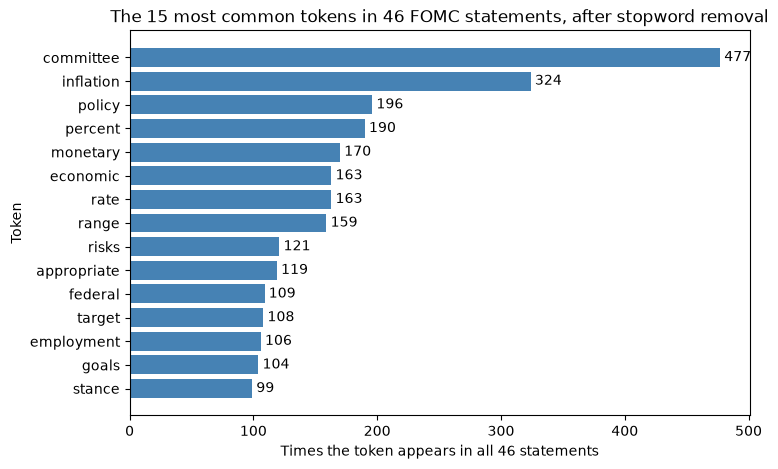

In [30]:
# most_common(15) gives the 15 highest counts as (token, count) pairs, and dict() makes them a Series
top15 = pd.Series(dict(all_counts.most_common(15)))

fig, ax = plt.subplots(figsize=(8, 5))

# horizontal bars, in reverse order, so that the most common token is at the top
bars = ax.barh(top15.index[::-1], top15.values[::-1], color='steelblue')

# the count at the end of each bar
ax.bar_label(bars, fmt='{:,.0f}', padding=3)

ax.set_title('The 15 most common tokens in 46 FOMC statements, after stopword removal')
ax.set_xlabel('Times the token appears in all 46 statements')
ax.set_ylabel('Token')

plt.show()

`committee` leads with 477, then `inflation` with 324.

The fifteenth is `stance` with 99.

Some of these tokens, such as `committee` and `federal`, are in every statement because of how a statement is written.

A count says how often a token appears.

It says nothing about what the statements say about it.

### A Document-Term Table

A **document-term table** has one row for each document and one column for each word of interest, and each cell is a count.

It is the standard way to hand text to anything that works on numbers.

Q. Build the table for eight words.

In [31]:
# eight plain words that appear in the statements
terms = ['committee', 'inflation', 'percent', 'economic', 'rate', 'risks', 'employment', 'labor']

# one Counter for each statement
counters = statements['kept'].apply(Counter)

# one column for each term: its count in every statement
term_table = pd.DataFrame({term: [counter[term] for counter in counters] for term in terms})
term_table.index = statements['date']

print(term_table.shape)
display(term_table.head().style.set_caption('Count of eight words in the first five statements'))
print(term_table.sum())

(46, 8)


,committee,inflation,percent,economic,rate,risks,employment,labor
date,,,,,,,,
2021-01-27,10,10,7,5,2,2,6,2
2021-03-17,10,10,8,5,2,2,6,2
2021-04-28,10,9,7,4,2,2,5,2
2021-06-16,10,9,7,3,2,2,5,2
2021-07-28,11,9,7,3,2,2,5,2


committee     477
inflation     324
percent       190
economic      163
rate          163
risks         121
employment    106
labor          62
dtype: int64


46 rows and 8 columns.

The first row says that in the statement dated 2021-01-27 the word `committee` appears 10 times, `inflation` 10, `percent` 7, `economic` 5, `rate` 2, `risks` 2, `employment` 6, and `labor` 2.

The column totals are 477 for `committee`, 324 for `inflation`, 190 for `percent`, 163 for `economic`, 163 for `rate`, 121 for `risks`, 106 for `employment`, and 62 for `labor`.

**Across the 46 statements the whole word rate appears 163 times.** Keep that number too.

The eight words were chosen because they are common, ordinary words in the file.

The table reports how often each appears.

It attaches no meaning to a count going up or down.

Q. Draw the table as a heatmap.

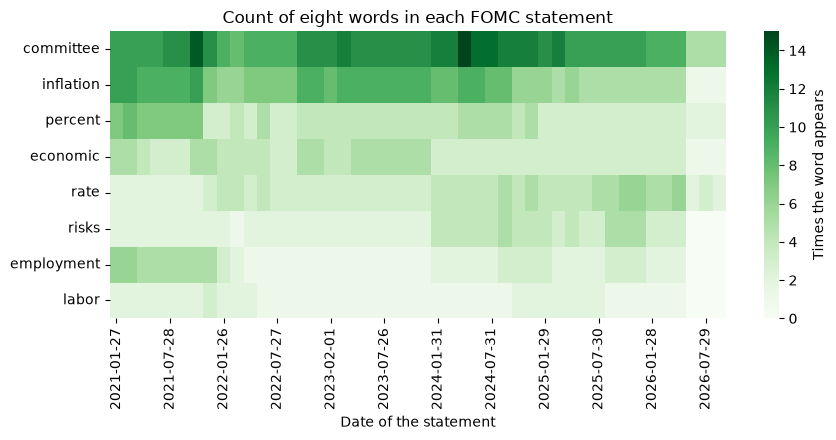

In [32]:
fig, ax = plt.subplots(figsize=(9, 4.5))

# .T turns the table on its side: one row for each word, one column for each statement
# xticklabels=4 labels every fourth statement, so the dates do not overlap. cbar_kws= labels the colour bar.
sns.heatmap(term_table.T, cmap='Greens', xticklabels=4, cbar_kws={'label': 'Times the word appears'}, ax=ax)

ax.set_title('Count of eight words in each FOMC statement')
ax.set_xlabel('Date of the statement')
ax.set_ylabel('')
fig.tight_layout()

plt.show()

Each column is a statement and each row is a word.

The darker the cell, the more often the word appears in that statement.

The `committee` row is the darkest, with counts from 5 to 15.

The `labor` row is the lightest, from 0 to 3.

The last three columns, the statements from 2026-06-17 on, are light in every row.

Those are also the three shortest statements, with 131, 167, and 131 words.

A count depends on how long the document is, which is the next question.

**Excel side by side.** The same picture is the table of counts with Home, Conditional Formatting, Color Scales applied to it.

Q. Build the table for every different token, then keep only the 50 most common.

In [33]:
# a table built from a list of Counters has one column for each different token. A token that a statement lacks is missing, and fillna(0) makes it 0.
full_table = pd.DataFrame(list(counters)).fillna(0).astype(int)
full_table.index = statements['date']
print('Statements and different tokens:', full_table.shape)

# the 50 tokens with the highest totals across the statements: a short vocabulary
top_tokens = full_table.sum().nlargest(50).index
top_table = full_table[top_tokens]
print('After keeping the 50 most common:', top_table.shape)

# the share of all kept tokens that the 50 cover
print('Share of the kept tokens covered:', round(top_table.sum().sum() / full_table.sum().sum() * 100, 1), 'percent')
print('Tokens that appear only once in the whole file:', (full_table.sum() == 1).sum())

Statements and different tokens: (46, 507)
After keeping the 50 most common: (46, 50)
Share of the kept tokens covered: 48.0 percent
Tokens that appear only once in the whole file: 70


`pd.DataFrame(list(counters))` gives one row for each statement and one column for each different token, 507 in all.

A token that a statement lacks is a missing value, and `fillna(0)` makes it a 0.

Keeping the 50 most common tokens shrinks the table from 46 by 507 to 46 by 50, and those 50 tokens still make up 48.0 percent of the 10,204 kept tokens.

70 tokens appear only once in the whole file.

A short vocabulary keeps the common words and drops the rare ones. scikit-learn, the machine learning library, has a class called `CountVectorizer` that builds this table in one step, with an option `max_features` that keeps only the most common words.

It uses its own rules for what a word is, so its counts can differ a little from these.

Here the table is built by hand, so that every step can be seen.

**Excel side by side.** The full table is a pivot table, with the statement in Rows, the token in Columns, and the count in Values, built from a sheet with one row for each token of each statement.

Q. Per 100 tokens, how often does each word appear, by year?

In [34]:
# div() with axis=0 divides each row of counts by the number of kept tokens in that statement, times 100
# .values gives the plain numbers, so that pandas divides row by row without matching labels
per_100 = term_table.div(statements['n_kept'].values, axis=0) * 100

# groupby() takes the 46 years directly, one for each row, and mean() works on each column within each year
per_100_by_year = per_100.groupby(statements['year'].values).mean()
per_100_by_year.index.name = 'year'

# each column shaded from its lowest year to its highest
display(per_100_by_year.style.format('{:.2f}').background_gradient(cmap='Greens', axis=0)
        .set_caption('Mentions per 100 tokens kept, by year'))

,committee,inflation,percent,economic,rate,risks,employment,labor
year,,,,,,,,
2021,3.47,2.93,2.13,1.32,0.68,0.64,1.69,0.68
2022,4.17,3.23,1.61,1.76,1.50,0.83,0.60,0.61
2023,5.18,4.13,1.86,2.21,1.40,0.93,0.47,0.47
2024,5.94,3.64,2.17,1.42,2.01,1.95,1.13,0.60
2025,5.05,2.57,1.46,1.46,2.30,1.94,1.22,0.80
2026,5.31,1.91,1.97,1.38,2.74,0.80,0.53,0.27


Per 100 tokens kept, `inflation` is 2.93 in 2021, 4.13 in 2023, and 1.91 in 2026, and `committee` is 3.47 in 2021 and 5.94 in 2024.

Dividing by the length puts a long statement and a short one on the same footing.

It is the text version of a market value weight: a count as a share of the total.

Q. What share of each year's statements contain a word at all?

In [35]:
# True where a statement contains the word at least once
check_words = ['employment', 'labor', 'balance', 'uncertain']
contains = pd.DataFrame({word: [word in tokens for tokens in statements['kept']] for word in check_words})

# the share of each year's statements, in percent
share = contains.groupby(statements['year'].values).mean() * 100
share.index.name = 'year'
display(share.style.format('{:.1f}').background_gradient(cmap='Blues', axis=None, vmin=0, vmax=100)
        .set_caption('Percent of each year\'s statements that contain the word'))

,employment,labor,balance,uncertain
year,,,,
2021,100.0,100.0,0.0,0.0
2022,100.0,100.0,75.0,25.0
2023,100.0,100.0,0.0,87.5
2024,100.0,100.0,100.0,100.0
2025,100.0,100.0,100.0,12.5
2026,50.0,50.0,50.0,16.7


`employment` and `labor` are in 100 percent of the statements of every year from 2021 to 2025, and in 50 percent of the six statements of 2026.

`balance` is in none of the 2021 statements, 75 percent in 2022, none in 2023, 100 percent in 2024 and 2025, and 50 percent in 2026.

`uncertain` is in none of the 2021 statements, 25 percent in 2022, 87.5 percent in 2023, 100 percent in 2024, 12.5 percent in 2025, and 16.7 percent in 2026.

`word in tokens` tests a list of whole tokens, so `uncertain` does not match `uncertainty`.

These are shares of documents that contain a word.

They are not a measure of anything else.

**Excel side by side.** With the year in column D and a TRUE or FALSE column for the word in column E, the share for one year is `=COUNTIFS(D2:D47, 2023, E2:E47, TRUE) / COUNTIF(D2:D47, 2023)`, which returns 0.875 for `uncertain` in 2023.

### How Much Wording Changed

Two statements can be compared by the words they share.

Take the set of different tokens in each.

The **Jaccard similarity** is the number of tokens in both sets divided by the number of tokens in either:

`similarity = tokens in both / tokens in either`

It is 1 when the two use exactly the same set of words and 0 when they share none.

**Predict 3**

Here are two short lists.

Three different words are in both, and the second list has `inflation` twice.

```
a = ['inflation', 'remains', 'elevated']
b = ['inflation', 'remains', 'somewhat', 'elevated', 'inflation']
```

What is their similarity?

> A) 0.6, which is 3 of the 5 items in the longer list.
>
> B) 0.75.
>
> C) 1, because every word of the first list is in the second.

Decide, then run the cell.

In [36]:
def similarity(first, second):
    # each list becomes a set: every different token once
    first_set = set(first)
    second_set = set(second)
    # & gives the tokens in both sets, and | gives the tokens in either
    return len(first_set & second_set) / len(first_set | second_set)


a = ['inflation', 'remains', 'elevated']
b = ['inflation', 'remains', 'somewhat', 'elevated', 'inflation']

# sorted() prints a set in alphabetical order
print('In both:', sorted(set(a) & set(b)))
print('In either:', sorted(set(a) | set(b)))
print('Similarity:', similarity(a, b))

In both: ['elevated', 'inflation', 'remains']
In either: ['elevated', 'inflation', 'remains', 'somewhat']
Similarity: 0.75


The answer is B. 3 tokens are in both and 4 are in either, so the similarity is 0.75.

`inflation` is in the second list twice and counts once.

A set ignores repeats and order.

The measure sees which words are used, not how often or where.

**Excel side by side.** `=UNIQUE(A2:A6)` gives each word once, the job of `set()`, in Excel 2021 and Microsoft 365.

With the 3 words of the first set in A2:A4 and the 4 words of the second in B2:B5, `=SUMPRODUCT(COUNTIF(B2:B5, A2:A4))` counts the words in both and returns 3.

The words in either are the two sets added, less the 3 counted twice: `=COUNTA(A2:A4) + COUNTA(B2:B5) - 3` returns 4, and 3 divided by 4 is 0.75.

Q. Compare each statement with the one before it.

In [37]:
# the first statement has nothing before it
values = [None]

# for every other statement, the similarity with the statement one row above
for i in range(1, len(statements)):
    values.append(similarity(statements['kept'].iloc[i], statements['kept'].iloc[i - 1]))

statements['similarity'] = values

print('Mean:', round(statements['similarity'].mean(), 3))

lowest = statements.loc[statements['similarity'].idxmin()]
highest = statements.loc[statements['similarity'].idxmax()]
print('Lowest:', lowest['date'], round(lowest['similarity'], 3))
print('Highest:', highest['date'], round(highest['similarity'], 3))
print('Below 0.7:', statements.loc[statements['similarity'] < 0.7, 'date'].tolist())

Mean: 0.832
Lowest: 2026-06-17 0.196
Highest: 2022-12-14 0.982
Below 0.7: ['2022-03-16', '2024-01-31', '2026-01-28', '2026-06-17', '2026-09-16']


On average, a statement shares 0.832 of its set of words with the one before it.

The highest value is 0.982, for the statement dated 2022-12-14 against the one before it.

The lowest is 0.196, for the statement dated 2026-06-17.

Five statements are below 0.7: those dated 2022-03-16, 2024-01-31, 2026-01-28, 2026-06-17, and 2026-09-16.

Q. Draw it.

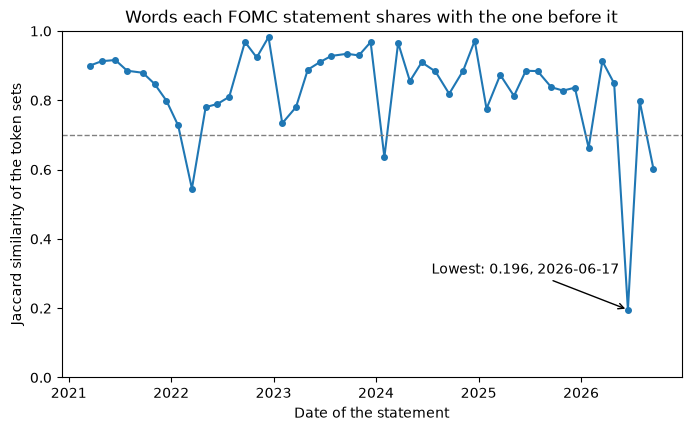

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(statements['meeting'], statements['similarity'], marker='o', markersize=4)

# a dashed line at 0.7, the level the five lowest points fall below, and a note on the lowest
ax.axhline(0.7, color='gray', linestyle='--', linewidth=1)
ax.annotate(f"Lowest: {lowest['similarity']:.3f}, {lowest['date']}", xy=(pd.to_datetime(lowest['date']), lowest['similarity']),
            xytext=(pd.to_datetime(lowest['date']) - pd.Timedelta(days=700), 0.3), arrowprops={'arrowstyle': '->'})

# the y axis runs over the whole possible range of the measure
ax.set_ylim(0, 1)
ax.set_title('Words each FOMC statement shares with the one before it')
ax.set_xlabel('Date of the statement')
ax.set_ylabel('Jaccard similarity of the token sets')

plt.show()

Most points lie between 0.7 and 1.

The five points below 0.7 are 0.545 on 2022-03-16, 0.636 on 2024-01-31, 0.663 on 2026-01-28, 0.196 on 2026-06-17, and 0.602 on 2026-09-16.

The chart measures **how much wording changed** from one statement to the next: a low point means many words were added or dropped.

It does not say which words they were or what a change means.

The measure treats every word alike.

The first statement has no value, because there is nothing before it.

`mean()` and the chart leave it out.

Q. Put the numbers together in the table the portfolio manager asked for.

In [39]:
# one row for each statement: its length, its figure, two word counts, and the similarity
summary = statements[['date', 'words', 'n_kept', 'range_text', 'inflation', 'similarity']].copy()
summary['similarity'] = summary['similarity'].round(3)

print(summary.shape)
summary.tail(6).style.format({'words': '{:,.0f}', 'n_kept': '{:,.0f}', 'inflation': '{:.0f}', 'similarity': '{:.3f}'}).hide(axis='index').set_caption('The last six statements')

(46, 6)


date,words,n_kept,range_text,inflation,similarity
2026-01-28,292,178,3‑1/2 to 3‑3/4 percent,5,0.663
2026-03-18,306,186,3‑1/2 to 3‑3/4 percent,5,0.913
2026-04-29,341,202,3‑1/2 to 3‑3/4 percent,5,0.849
2026-06-17,131,80,3-1/2 to 3-3/4 percent,1,0.196
2026-07-29,167,101,3-1/2 to 3-3/4 percent,1,0.798
2026-09-16,131,79,3-3/4 to 4 percent,1,0.602


46 rows and 6 columns.

Every cell is a count, a figure copied from the text, or a ratio of counts, and every one can be checked against the published statement.

That is where this notebook stops.

The table describes the wording of 46 documents.

What the documents mean is not in it.

## You Can Now

By the end of this notebook, you can:

* Clean text in steps: lower case, remove what is not a letter, reduce white space, split into tokens.
* Remove stopwords with a list of your own and with nltk's list, and stem tokens with the Porter stemmer, knowing its limits.
* Count tokens with `Counter`.
* Spot a character that looks like another with `ascii()`, and widen a pattern to take it in.
* Work on a whole column with `.str.lower()`, `.str.len()`, `.str.contains()`, `.str.count()`, `.str.findall()`, and `.apply()`.
* Build a document-term table, keep the most common words, draw it as a heatmap, and compare documents by the words they share.
* Match each step to Excel: `REGEXREPLACE`, `COUNTIF`, `COUNTIFS`, `FILTER`, `SUMPRODUCT`, `UNICODE`, `UNICHAR`, `UNIQUE`, a pivot table of tokens, and Color Scales.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Exercise 1 uses a second statement, the one dated 2022-09-21, stored as `other`.

Exercises 2 and 3 use the whole table, and so do the two AI checks, exercises 4 and 5.

Every answer is a count, a figure, or a piece of text taken from a file.

None is a reading of what a statement means.

Replace each `...` with your own code, then run the check cell.

Print the numbers you rely on.

Run the next cell first.

It imports the libraries, defines `check`, a small function that marks your answers, defines `clean()` as in the lesson, loads nltk's stopword list as `stop_words`, and loads a fresh `statements`.

It prints the shape of the table, (46, 3), the number of stopwords, 198, and the type of `other`.

In [40]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


def clean(text):
    # the four cleaning steps of the lesson: lower case, letters only, single spaces, tokens
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split(' ')


# nltk's English stopword list, downloaded once
ready = nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop_words = stopwords.words('english')

# a fresh copy of the statements. In Colab the file is read from GitHub.
if os.path.exists('../../../data/fomc_statements.csv'):
    data_file = '../../../data/fomc_statements.csv'
else:
    data_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/fomc_statements.csv'

statements = pd.read_csv(data_file)

# the statement the first exercise uses
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]

print(statements.shape)
print(len(stop_words))
print(type(other))

(46, 3)
198
<class 'str'>


### Exercise 1

Q. Clean `other` with `clean()`. How many tokens are there? Remove nltk's stopwords. How many are left, and which token is the most common? Store the answers in **ex1_tokens**, **ex1_kept**, and **ex1_top**.

In [41]:
ex1_tokens = ...
ex1_kept = ...
ex1_top = ...

In [42]:
check('Exercise 1 tokens', ex1_tokens, 315)
check('Exercise 1 kept', ex1_kept, 201)
check('Exercise 1 most common', ex1_top, 'committee')

Exercise 1 tokens: not attempted yet
Exercise 1 kept: not attempted yet
Exercise 1 most common: not attempted yet


### Exercise 2

Q. On the whole table: add a `words` column with the word count of each statement by `split()`, and a `year` column. Which year has the highest mean word count, and what is that mean? Store them in **ex2_year** and **ex2_mean**, the mean rounded to 1 decimal place. Then count the statements that contain the whole word `uncertain`, capitals ignored, and store the count in **ex2_uncertain**. Draw the mean word count by year as a bar chart.

In [43]:
ex2_year = ...
ex2_mean = ...
ex2_uncertain = ...

In [44]:
check('Exercise 2 year', ex2_year, 2021)
check('Exercise 2 mean words', ex2_mean, 505.5)
check('Exercise 2 uncertain', ex2_uncertain, 19)

Exercise 2 year: not attempted yet
Exercise 2 mean words: not attempted yet
Exercise 2 uncertain: not attempted yet


### Exercise 3

Q. Build the document-term table for every different token. For each statement, clean the text with `clean()` and keep the tokens that are not in `stop_words`. Make a `Counter` of each statement's kept tokens and a table with one row for each statement and one column for each token. How many different tokens are there, and what share of all the kept tokens, in percent rounded to 1 decimal place, do the 20 most common cover? Store them in **ex3_vocabulary** and **ex3_share**.

In [45]:
ex3_vocabulary = ...
ex3_share = ...

In [46]:
check('Exercise 3 different tokens', ex3_vocabulary, 507)
check('Exercise 3 share covered', ex3_share, 30.0)

Exercise 3 different tokens: not attempted yet
Exercise 3 share covered: not attempted yet


### Exercise 4: AI check

You ask an AI assistant to pull the range out of every statement and say how many statements have one.

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It runs without an error, and it contains one bug.

Q. Read the code before you run it. How many statements should have a range? The lesson worked it out. Then run the code. Does the answer agree with you?

In [47]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# a number, the word to, a number, and percent
pattern = r'\d+ to \d+ percent'

found = statements['text'].str.findall(pattern)

# the number of statements with at least one match
ex4_statements = int((found.str.len() > 0).sum())

# the matches themselves
print(found[found.str.len() > 0].tolist())
print('Statements with a range:', ex4_statements)

[['4 to 1 percent'], ['4 to 4 percent'], ['4 to 5 percent'], ['4 to 5 percent'], ['4 to 4 percent'], ['4 to 4 percent']]
Statements with a range: 6


Q. Find the bug and fix the code in the cell above, so that **ex4_statements** holds the right count. Then store the range found in the first statement, as text, in **ex4_first**.

In [48]:
ex4_first = ...

In [49]:
check('Exercise 4 statements with a range', ex4_statements, 46)
check('Exercise 4 first range', ex4_first, '0 to 1/4 percent')

Exercise 4 statements with a range: not yet. You have 6
Exercise 4 first range: not attempted yet


### Exercise 5: AI check

You ask an AI assistant: how many times does the word rate appear in the statements?

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It runs without an error, and it contains one bug.

Q. Read the code before you run it. The lesson has two numbers for this, one from each part: the word rate appears 3 times in the statement dated 2023-11-01, and 163 times across the 46 statements. What will this code print?

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# count the word 'rate' in one statement and in all statements
one = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
ex5_one = one.count('rate')
print('In the statement dated 2023-11-01:', ex5_one)

ex5_total = statements['text'].str.count('rate').sum()
print('In all 46 statements:', ex5_total)

In the statement dated 2023-11-01: 4
In all 46 statements: 188


Q. Find the bug and fix the code in the cell above, so that **ex5_one** and **ex5_total** hold the right counts.

In [51]:
check('Exercise 5 one statement', ex5_one, 3)
check('Exercise 5 all statements', ex5_total, 163)

Exercise 5 one statement: not yet. You have 4
Exercise 5 all statements: not yet. You have 188


## Congratulations!

You made it through Analyzing Text, Part 2.

When this part began, a statement was still one long string.

Now you can clean it in steps and count it.

You did the same to all 46 statements, and each result became a column of numbers.

The best moment was a quiet one.

A pattern found 41 ranges where there should be 46, and you went looking, and found a hyphen no eye can see.

Testing a result against a count from somewhere else is the habit that catches what looks right.

Be proud of that.

Next, in Case Study: Statement Sentiment, these tools meet one question from the desk: can the wording of a statement be turned into a single number, and how far can that number be trusted?